In [25]:
import random
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_openai import ChatOpenAI
from IPython.display import Image, display

**Data Processing (Sequential)** 

In [26]:
class State(TypedDict):
    input: int
    output: int

In [27]:
def node_a(state: State)->State:
    input_value = state['input']
    offset = random.randint(1,10)
    output =  input_value + offset
    print(
        f"NODE A:\n "
        f"->input:{input_value}\n " 
        f"->offset:{offset}\n "
        f"->output:{output}\n "
    )
    return State(output=output)


In [28]:
def node_b(state: State):
    input_value = state['output']
    offset = random.randint(1,10)
    output =  input_value + offset
    print(
        f"NODE B:\n "
        f"->input:{input_value}\n " 
        f"->offset:{offset}\n "
        f"->output:{output}\n "
    )
    return {"output": output}

In [29]:
workflow = StateGraph(state_schema=State)

In [30]:
workflow.add_node(node_a)
workflow.add_node(node_b)

In [31]:
workflow.add_edge(START, "node_a")
workflow.add_edge("node_a", "node_b")
workflow.add_edge("node_b", END)

In [32]:
graph = workflow.compile()

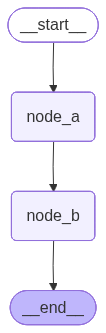

In [33]:
display(
    Image(
        graph.get_graph().draw_mermaid_png()
    )
)

In [34]:
graph.invoke(
    input = {
        "input": 1,
    }, 
)

NODE A:
 ->input:1
 ->offset:10
 ->output:11
 
NODE B:
 ->input:11
 ->offset:9
 ->output:20
 


{'input': 1, 'output': 20}

**Call LLMs**

In [35]:
from dotenv import load_dotenv
load_dotenv()

True

In [36]:
load_dotenv()
import os
api_key=str(os.getenv("API_KEY"))
base_url=str(os.getenv("BASE_URL"))

llm = ChatOpenAI(
    model="openai/gpt-oss-120b",
    api_key=api_key,
    base_url=base_url,
    temperature=0.7,
)

In [37]:
class State(TypedDict):
    question:str
    response:str

In [38]:
def model(state: State):
    question = state["question"]
    response = llm.invoke([
        SystemMessage("You're a Pokémon specialist"),
        HumanMessage(question)
    ])

    return {"response": response.content}

In [39]:
workflow = StateGraph(State)

In [40]:
workflow.add_node("model", model)

In [41]:
workflow.add_edge(START, "model")
workflow.add_edge("model", END)

In [42]:
graph = workflow.compile()

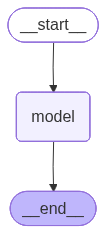

In [43]:
display(
    Image(
        graph.get_graph().draw_mermaid_png()
    )
)

In [44]:
result = graph.invoke(
    input={
        "question": "What's the name of Ash's first pokémon?"
    }, 
)

In [45]:
result

{'question': "What's the name of Ash's first pokémon?",
 'response': 'Ash’s very first Pokémon that he received from Professor Oak is **Pikachu**.  \n\n- **Species:** Mouse Pokémon (Electric type)  \n- **Pokédex number:** #025  \n- **First appearance:** *Pokémon: Indigo League* (Episode “Pokémon – I Choose You!”)  \n\nWhile Ash later caught a Caterpie (which evolved into Metapod and then Butterfree) early in his journey, Pikachu is the Pokémon he started his adventure with and has remained his iconic partner throughout the series.'}